# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

Работу выполнил Алёшкин Дмитрий, группа: J3311, ИСУ: 464975.

Реализация для Google Colab с GPU T4. Основная модель: [RuBERT-tiny2](https://huggingface.co/cointegrated/rubert-tiny2), лицензия MIT; для сравнения: [RuBERT-tiny](https://huggingface.co/cointegrated/rubert-tiny), MIT. Данные: [WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural), русский язык, CC BY-NC-SA 4.0.

`FAST_MODE=True` — диагностический эксперимент на ограниченной выборке, **не итоговая оценка качества**. После проверки переключите `FAST_MODE=False` и выполните «Среда выполнения → Перезапустить и выполнить все». Графики, метрики и выводы ниже вычисляются заново из результатов текущего запуска.


## Сведения о сдаче

- Устройство полного прогона — Google Colab, Tesla T4.
- Модели — [RuBERT-tiny2](https://huggingface.co/cointegrated/rubert-tiny2) и [RuBERT-tiny](https://huggingface.co/cointegrated/rubert-tiny), MIT.
- Данные — [WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural), русский язык, CC BY-NC-SA 4.0.
- Источники — шаблон ДЗ-2 и его открытые тесты, [Transformers Trainer](https://huggingface.co/docs/transformers/main_classes/trainer), [seqeval](https://github.com/chakki-works/seqeval).
- Выполнены 1–5 и 6.2–6.5. Для 6.1 требуется дополнительная ручная разметка.


In [1]:
%pip install -q "pyarrow==23.0.1" "transformers==5.22.0" "datasets==4.8.5" "accelerate==1.15.0" "seqeval==1.2.2" "numpy" "matplotlib"


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

# Проверяем именно конфликт pyarrow/cuDF (и сохраняем воспроизводимость окружения).
import pyarrow as pa
from importlib.metadata import version as package_version, PackageNotFoundError
from packaging.version import Version
arrow_version = Version(pa.__version__)
assert Version('19') <= arrow_version < Version('24'), (
    f'pyarrow={pa.__version__}: для имеющегося в Colab cudf-cu13 нужен диапазон [19, 24)'
)
try:
    cudf_version = package_version('cudf-cu13')
except PackageNotFoundError:
    cudf_version = None
print(f'pyarrow {pa.__version__}; cudf-cu13 {cudf_version or "не установлен"}; совместимый диапазон проверен')


torch 2.11.0+cu130, transformers 5.22.0, datasets 4.8.5
CUDA available: True
pyarrow 23.0.1; cudf-cu13 26.6.0; совместимый диапазон проверен


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [4]:
FAST_MODE = False  # пробный запуск; для итогового эксперимента — False
BONUS_TASKS = {'6.1', '6.2', '6.3', '6.4', '6.5'}
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}
SEED = 0
N_TRAIN = 1200 if FAST_MODE else 15000
N_EVAL = 240 if FAST_MODE else 2000
EPOCHS = 3
MAX_LENGTH = 128
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES, BONUS_RESULTS, ANSWERS = {}, {}, {}

def answer(section, text):
    from IPython.display import display, Markdown
    ANSWERS[section] = text
    display(Markdown('**Ответ ' + section + '.** ' + text))
    (ARTIFACTS / 'answers.md').write_text('\n\n'.join('## '+k+'\n'+v for k,v in ANSWERS.items()), encoding='utf-8')

def save_json(name, value):
    (ARTIFACTS / name).write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

# Один lock-файл на основной и повторный запуск; вложить его в пакет результатов.
LOCK_PATH = Path('revisions.json')
LOCK = json.loads(LOCK_PATH.read_text()) if LOCK_PATH.exists() else {}
def locked_revision(repo, kind='model'):
    key = kind + ':' + repo
    if key not in LOCK:
        api = HfApi()
        LOCK[key] = (api.model_info(repo) if kind == 'model' else api.dataset_info(repo)).sha
        LOCK_PATH.write_text(json.dumps(LOCK, indent=2))
    assert re.fullmatch(r'[0-9a-f]{40}', LOCK[key])
    save_json('revisions.json', LOCK)
    return LOCK[key]


---
# 1. Модель

## 1.1 Модель и ревизия

Выбран предобученный энкодер на Hugging Face Hub, подходящий под язык и домен нашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'cointegrated/rubert-tiny2'
REVISION = locked_revision(MODEL_ID)
TOKENIZER_KWARGS = {}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}


config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** RuBERT-tiny2 — небольшой русскоязычный энкодер с поддержкой английского, предобученный для языковых задач, а не готовый NER-классификатор. По карточкам tiny2 имеет около 29M параметров, tiny — около 12M; больше словарь tiny2, поэтому меньше фрагментация русских слов, но больше память эмбеддингов. RuBERT-base существенно тяжелее (около 180M), поэтому для ограниченного бюджета выбран tiny2. Карточка tiny2 сообщает улучшения на русских NLU-задачах, однако это не доказательство превосходства на нашем NER: его проверяет 6.2. Лицензия MIT требует сохранения уведомления об авторстве и лицензии. Commit hash фиксируется при первом запуске в revisions.json, последующие запуски используют тот же hash; без фиксации могут измениться веса, словарь и предсказания. Скорость измеряется в 1.2 и 6.2, чужие результаты не выдаются за наши.

## 1.2 Архитектура

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

model.safetensors: reconstructing file:   0%|          |  0.00B /  118MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    base = model.base_model
    emb = base.embeddings
    encoder = getattr(base, 'encoder', getattr(base, 'transformer', None))
    layers = getattr(encoder, 'layer', getattr(encoder, 'layers', None))
    if layers is None:
        raise ValueError('Unknown encoder layout: inspect named_modules')
    groups = [list(emb.parameters()), [p for layer in layers for p in layer.parameters()], list(model.classifier.parameters())]
    used = set()
    counts = []
    for group in groups:
        unique = {id(p):p for p in group if id(p) not in used}
        counts.append(sum(p.numel() for p in unique.values()))
        used.update(unique)
    return dict(zip(['embeddings','encoder','head'], counts),
                other=sum(p.numel() for p in model.parameters() if id(p) not in used),
                layers=[sum(p.numel() for p in l.parameters()) for l in layers])

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


### 1.2.1. Визуализация распределения параметров

По числу параметров доминируют эмбеддинги; это не означает, что большая часть арифметических операций приходится на них. Вычислительная нагрузка внимания и feed-forward-слоёв зависит от длины последовательности.

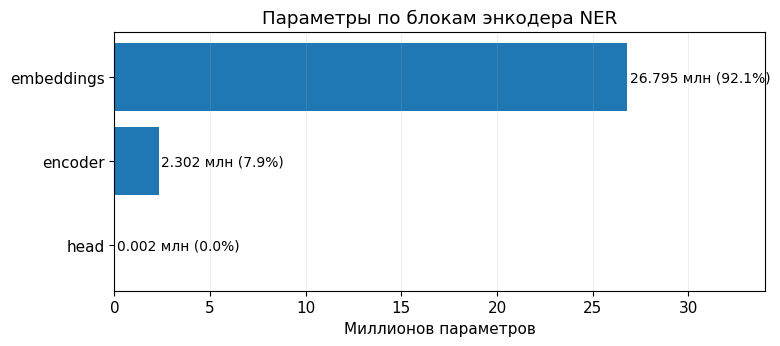

Словарь составляет 83,828 токенов; 92.1% параметров приходится на embeddings.


In [10]:
parts = ['embeddings','encoder','head']
values = [blocks[k] for k in parts]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(parts[::-1], [v/1e6 for v in values[::-1]])
ax.set_xlabel('Миллионов параметров')
ax.set_title('Параметры по блокам энкодера NER')
for idx, v in enumerate(values[::-1]):
    ax.text(v/1e6+0.15, idx, f'{v/1e6:.3f} млн ({v/total:.1%})', va='center', fontsize=10)
ax.set_xlim(0, max(values)/1e6*1.27)
ax.grid(axis='x', alpha=.2)
plt.tight_layout(); plt.savefig(ARTIFACTS/'model_parameters.png', dpi=150); plt.show()
print(f'Словарь составляет {cfg.vocab_size:,} токенов; {blocks["embeddings"]/total:.1%} параметров приходится на embeddings.')


In [11]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)
print('input_ids', tuple(enc.input_ids.shape), 'attention_mask', tuple(enc.attention_mask.shape))
print('hidden_states', [tuple(h.shape) for h in out.hidden_states], 'logits', tuple(out.logits.shape))
answer('1.2', f'Всего параметров {total:,}; по блокам: {blocks}. Вход {tuple(enc.input_ids.shape)}, logits {tuple(out.logits.shape)}. Токены обмениваются информацией в attention энкодера; lookup эмбеддингов и линейная голова работают по позициям. T включает сабворды и специальные токены, поэтому обычно больше числа слов.')

input_ids (2, 11) attention_mask (2, 11)
hidden_states [(2, 11, 312), (2, 11, 312), (2, 11, 312), (2, 11, 312)] logits (2, 11, 7)


**Ответ 1.2.** Всего параметров 29,098,303; по блокам: {'embeddings': 26794560, 'encoder': 2301552, 'head': 2191, 'other': 0, 'layers': [767184, 767184, 767184]}. Вход (2, 11), logits (2, 11, 7). Токены обмениваются информацией в attention энкодера; lookup эмбеддингов и линейная голова работают по позициям. T включает сабворды и специальные токены, поэтому обычно больше числа слов.

In [12]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 8.0 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из нашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ.** Вход и маска имеют форму (2, 11). Каждый из трёх слоёв энкодера сохраняет размер скрытого представления 312. Голова выдаёт логиты (2, 11, 7) для семи демонстрационных тегов. Из 29 098 303 параметров 26 794 560 (92,1%) приходятся на эмбеддинги, 2 301 552 — на энкодер и 2 191 — на голову.

---
# 2. Данные

## 2.1 Датасет

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [13]:
DATASET_ID, DATASET_CONFIG = 'Babelscape/wikineural', None
DATASET_REVISION = locked_revision(DATASET_ID, 'dataset')
# Загружаем только русские сплиты, а не все девять языков.
raw = DatasetDict({target: load_dataset(DATASET_ID, revision=DATASET_REVISION, split=source)
                   for target, source in [('train','train_ru'),('validation','val_ru'),('test','test_ru')]})
LABEL_NAMES = ['O','B-PER','I-PER','B-ORG','I-ORG','B-LOC','I-LOC','B-MISC','I-MISC']
# Удаляем точные дубликаты внутри и между сплитами; train имеет приоритет.
seen, audit = set(), {}
for split in ['train','validation','test']:
    keep, duplicates = [], 0
    for i, ex in enumerate(raw[split]):
        assert len(ex['tokens']) == len(ex['ner_tags'])
        assert all(0 <= t < len(LABEL_NAMES) for t in ex['ner_tags'])
        key = tuple(ex['tokens'])
        if key in seen:
            duplicates += 1
        else:
            seen.add(key); keep.append(i)
    raw[split] = raw[split].select(keep)
    audit[split] = dict(kept=len(keep), removed_duplicates=duplicates)
save_json('data_audit.json', audit)
print(audit)

README.md:   0%|          | 0.00/5.27k [00:00<?, ?B/s]

data/test_de-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  847kB            

data/test_de-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test_en-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  894kB            

data/test_en-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test_es-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  723kB            

... (73 outputs left out)

Generating val_pl split: 0 examples [00:00, ? examples/s]

Generating val_pt split: 0 examples [00:00, ? examples/s]

Generating val_ru split: 0 examples [00:00, ? examples/s]

{'train': {'kept': 92320, 'removed_duplicates': 0}, 'validation': {'kept': 11540, 'removed_duplicates': 0}, 'test': {'kept': 11580, 'removed_duplicates': 0}}


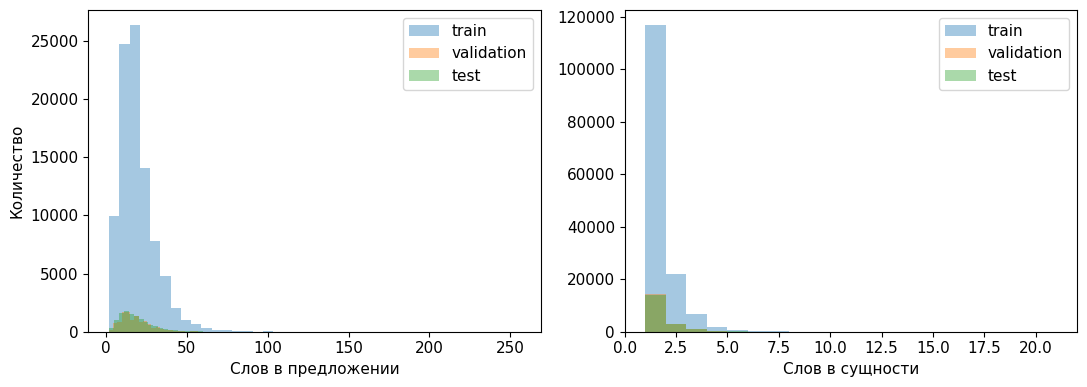

**Ответ 2.1.** WikiNEuRal: автоматическая разметка Wikipedia с BabelNet и BERT, CC BY-NC-SA 4.0. Статистика после удаления дубликатов: {'train': {'sentences': 92320, 'entities': {'LOC': 71090, 'PER': 33282, 'MISC': 23594, 'ORG': 20236}, 'mean_sentence_words': 19.610669410745235, 'mean_span_words': 1.3126071173128568}, 'validation': {'sentences': 11540, 'entities': {'ORG': 2710, 'LOC': 8851, 'MISC': 2642, 'PER': 4007}, 'mean_sentence_words': 18.78838821490468, 'mean_span_words': 1.3194398682042834}, 'test': {'sentences': 11580, 'entities': {'LOC': 8596, 'PER': 3489, 'MISC': 2962, 'ORG': 3051}, 'mean_sentence_words': 18.773056994818653, 'mean_span_words': 1.3563929715990717}}. Используем фиксированные подмножества для вычислительного бюджета, размеры указаны в конфигурации; разметка может содержать шум и неоднозначный MISC. Источник: https://huggingface.co/datasets/Babelscape/wikineural .

In [14]:
# BIO-парсер для статистики: библиотечный; собственная реализация ниже.
from seqeval.metrics.sequence_labeling import get_entities
stats = {}
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for split, ds in raw.items():
    counts, span_lengths, sentence_lengths = collections.Counter(), [], []
    for ex in ds:
        tags = [LABEL_NAMES[t] for t in ex['ner_tags']]
        sentence_lengths.append(len(tags))
        for typ, a, b in get_entities(tags):
            counts[typ] += 1; span_lengths.append(b-a+1)
    stats[split] = dict(sentences=len(ds), entities=dict(counts),
                        mean_sentence_words=float(np.mean(sentence_lengths)),
                        mean_span_words=float(np.mean(span_lengths)))
    axs[0].hist(sentence_lengths, bins=40, alpha=.4, label=split)
    axs[1].hist(span_lengths, bins=range(1,22), alpha=.4, label=split)
axs[0].set(xlabel='Слов в предложении', ylabel='Количество'); axs[1].set(xlabel='Слов в сущности')
for ax in axs: ax.legend()
plt.tight_layout(); plt.savefig(ARTIFACTS/'data_lengths.png'); plt.show()
save_json('dataset_statistics.json', stats)
answer('2.1', f'WikiNEuRal: автоматическая разметка Wikipedia с BabelNet и BERT, CC BY-NC-SA 4.0. Статистика после удаления дубликатов: {stats}. Используем фиксированные подмножества для вычислительного бюджета, размеры указаны в конфигурации; разметка может содержать шум и неоднозначный MISC. Источник: https://huggingface.co/datasets/Babelscape/wikineural .')

### 2.1.1. Баланс типов сущностей и длина спанов

Сравниваем не только абсолютные количества, но и число сущностей каждого типа на 1000 предложений: размеры исходных разбиений различаются. Сильный перекос классов влияет на обучение NER.

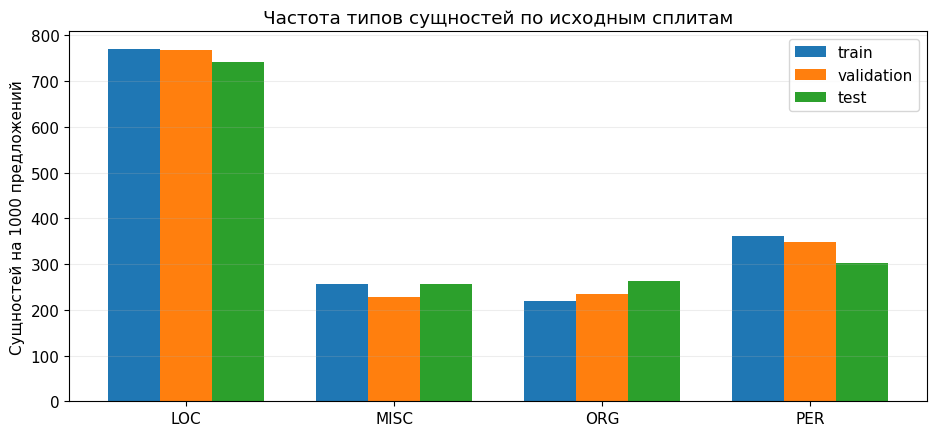

train: 92,320 предложений, 148,202 сущностей, средняя длина предложения 19.61 слова, длина сущности 1.31 слова
validation: 11,540 предложений, 18,210 сущностей, средняя длина предложения 18.79 слова, длина сущности 1.32 слова
test: 11,580 предложений, 18,098 сущностей, средняя длина предложения 18.77 слова, длина сущности 1.36 слова


In [15]:
entity_types_plot = sorted({t for s in stats.values() for t in s['entities']})
split_names = list(stats)
x = np.arange(len(entity_types_plot))
fig, ax = plt.subplots(figsize=(9.5, 4.5))
width = .25
for j, split in enumerate(split_names):
    s = stats[split]
    vals = [s['entities'].get(t,0)*1000/s['sentences'] for t in entity_types_plot]
    ax.bar(x+(j-1)*width, vals, width, label=split)
ax.set_xticks(x, entity_types_plot)
ax.set_ylabel('Сущностей на 1000 предложений')
ax.set_title('Частота типов сущностей по исходным сплитам')
ax.grid(axis='y', alpha=.22); ax.legend()
plt.tight_layout(); plt.savefig(ARTIFACTS/'entity_frequency.png', dpi=150); plt.show()
for split in split_names:
    s=stats[split]
    print(f'{split}: {s["sentences"]:,} предложений, '+
          f'{sum(s["entities"].values()):,} сущностей, средняя длина предложения '+
          f'{s["mean_sentence_words"]:.2f} слова, длина сущности {s["mean_span_words"]:.2f} слова')


**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ.** WikiNEuRal — автоматически размеченные тексты Wikipedia с использованием BabelNet и BERT. Русская часть распространяется по CC BY-NC-SA 4.0. После удаления точных дубликатов осталось 92 320 / 11 540 / 11 580 предложений train / validation / test. Число сущностей LOC / PER / ORG / MISC соответственно: train — 71 090 / 33 282 / 20 236 / 23 594, validation — 8 851 / 4 007 / 2 710 / 2 642, test — 8 596 / 3 489 / 3 051 / 2 962. LOC преобладает во всех сплитах. Средняя длина сущности 1,31–1,36 слова, предложения — 18,77–19,61 слова. Дисбаланс и шум автоматической разметки могут влиять на качество по отдельным типам.

## 2.2 Формат разметки

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [16]:
def bio_to_spans(tags):
    spans, start, typ = [], None, None
    for i, tag in enumerate(list(tags) + ['O']):
        if tag == 'O': prefix, newtyp = 'O', None
        else:
            prefix, newtyp = tag.split('-', 1)
            if prefix not in {'B','I'} or not newtyp: raise ValueError(tag)
        continuing = prefix == 'I' and start is not None and newtyp == typ
        if not continuing:
            if start is not None: spans.append((start, i, typ))
            start, typ = (i, newtyp) if prefix != 'O' else (None, None)
    return spans


def spans_to_bio(spans, n_words):
    if n_words < 0: raise ValueError('negative length')
    tags = ['O'] * n_words
    for a,b,t in sorted(spans):
        if not (0 <= a < b <= n_words) or not t: raise ValueError('invalid span')
        if any(x != 'O' for x in tags[a:b]): raise ValueError('overlapping spans')
        tags[a:b] = ['B-'+t] + ['I-'+t]*(b-a-1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    result, seen = [], set()
    for w in word_ids:
        if w is None: result.append(-100); continue
        if not 0 <= w < len(word_labels): raise ValueError('word id out of bounds')
        tag = word_labels[w]
        result.append(tag if w not in seen else (-100 if b_to_i is None else b_to_i.get(tag, tag)))
        seen.add(w)
    return result

In [17]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [18]:
Path('data').mkdir(exist_ok=True)
roundtrip = {}
for split, ds in raw.items():
    path = Path('data') / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as f:
        for ex in ds:
            tags = [LABEL_NAMES[t] for t in ex['ner_tags']]
            f.write(json.dumps(dict(tokens=ex['tokens'], spans=bio_to_spans(tags)), ensure_ascii=False)+'\n')
    changed = 0
    with path.open(encoding='utf-8') as f:
        for ex, line in zip(ds, f):
            obj = json.loads(line)
            assert obj['tokens'] == ex['tokens']
            original = [LABEL_NAMES[t] for t in ex['ner_tags']]
            back = spans_to_bio(obj['spans'], len(obj['tokens']))
            assert bio_to_spans(back) == bio_to_spans(original)
            changed += original != back
    roundtrip[split] = dict(checked=len(ds), noncanonical_bio=changed)
save_json('roundtrip.json', roundtrip)
print(roundtrip)

{'train': {'checked': 92320, 'noncanonical_bio': 3210}, 'validation': {'checked': 11540, 'noncanonical_bio': 393}, 'test': {'checked': 11580, 'noncanonical_bio': 464}}


In [19]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    full_encoding = tokenizer(
        ex['tokens'], is_split_into_words=True, truncation=False, verbose=False
    )
    n_truncated += len(full_encoding['input_ids']) > MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

answer('2.2', f'Проверка JSON туда-обратно: {roundtrip}. В train слов потеряно из-за ограничения длины или токенизации: {n_lost_words}; числом обрезанных предложений: {n_truncated}. -100 исключает специальные токены и продолжения из cross-entropy, чтобы каждое слово имело один вклад. При инференсе потерянные слова получают O и остаются в знаменателе метрик; длинные сущности могут быть пропущены.')

Map:   0%|          | 0/15000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 15000
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 2000
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']
train: проверено 14989 предложений, обрезано по MAX_LENGTH 11, слов без сабвордов или за обрезкой 213
[CLS]            None  -100
Работы              0  O
по                  1  O
строительству       2  O
первоначальной      3  O
инфраструктуры      4  O
аэропорта           5  O
начались            6  O
в                   7  O
1937                8  O
году                9  O
на                 10  O
месте              11  O
девяти             12  O
сельскохозяйственных   13  O
угодий             14  O
,                  15  O
выкуп              16  O
##ленных           16  -100
муниципальным      17  O
комитетом          1

**Ответ 2.2.** Проверка JSON туда-обратно: {'train': {'checked': 92320, 'noncanonical_bio': 3210}, 'validation': {'checked': 11540, 'noncanonical_bio': 393}, 'test': {'checked': 11580, 'noncanonical_bio': 464}}. В train слов потеряно из-за ограничения длины или токенизации: 213; числом обрезанных предложений: 11. -100 исключает специальные токены и продолжения из cross-entropy, чтобы каждое слово имело один вклад. При инференсе потерянные слова получают O и остаются в знаменателе метрик; длинные сущности могут быть пропущены.

### 2.2.1. Распределение BIO-тегов и доля класса `O`

NER — задача с сильным дисбалансом между словами вне сущностей и словами, входящими в сущности. Доли считаются по словам в выбранной обучающей выборке, а не по сабвордам. Большая доля `O` может привести к тривиальной стратегии предсказывать только этот тег.

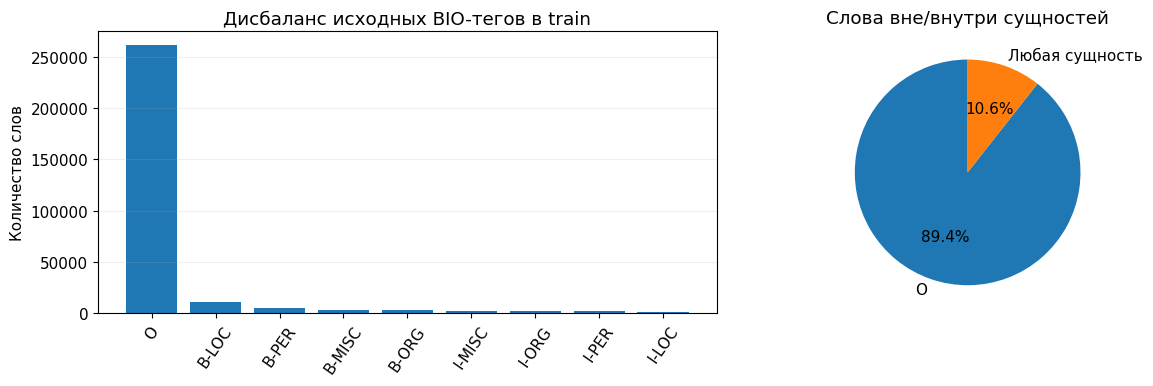

Всего слов в обучающем подмножестве: 292,863; O: 261,767 (89.4%).
Присутствуют типы: ['LOC', 'MISC', 'ORG', 'PER']. Доля сущностей по словам: 10.6%.


In [20]:
word_tag_counts = collections.Counter(LABEL_NAMES[t] for ex in data['train'] for t in ex['ner_tags'])
total_words = sum(word_tag_counts.values())
o_fraction = word_tag_counts['O']/max(total_words,1)
ordered_labels = sorted(word_tag_counts, key=lambda z:(z!='O',-word_tag_counts[z]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(ordered_labels, [word_tag_counts[t] for t in ordered_labels])
axes[0].tick_params(axis='x', rotation=55)
axes[0].set_ylabel('Количество слов')
axes[0].set_title('Дисбаланс исходных BIO-тегов в train')
axes[0].grid(axis='y', alpha=.2)
axes[1].pie([word_tag_counts['O'], total_words-word_tag_counts['O']], labels=['O','Любая сущность'],
            autopct='%1.1f%%', startangle=90)
axes[1].set_title('Слова вне/внутри сущностей')
plt.tight_layout(); plt.savefig(ARTIFACTS/'label_balance.png', dpi=150); plt.show()
print(f'Всего слов в обучающем подмножестве: {total_words:,}; O: {word_tag_counts["O"]:,} ({o_fraction:.1%}).')
print(f'Присутствуют типы: {ENTITY_TYPES}. Доля сущностей по словам: {1-o_fraction:.1%}.')


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ.** Метка назначается первому сабворду. Значение `-100` исключает продолжения слов и специальные токены из функции потерь, чтобы каждое слово имело один вклад. В полном train-прогоне обрезано 11 предложений, 213 слов не получили представления после токенизации и обрезки. При оценке такие слова получают O, что может снизить recall. BIO → интервалы → BIO сохранило сущности, при этом запись тегов нормализовалась у 3 210 / 393 / 464 предложений train / validation / test.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [21]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [22]:
def fit_majority_tagger(tokens_list, tags_list):
    if len(tokens_list) != len(tags_list): raise ValueError('sentence count mismatch')
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        if len(words) != len(tags): raise ValueError('length mismatch')
        for w,t in zip(words,tags): counts[w][t] += 1
    return {w: sorted(c, key=lambda t:(-c[t],t))[0] for w,c in counts.items()}


def predict_majority(tagger, words):
    return [tagger.get(w, 'O') for w in words]

In [23]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

baseline = {}   # ваш код: baseline['majority'] и baseline['random_head'] - словари entity_scores
train_gold = [[LABEL_NAMES[t] for t in ts] for ts in data['train']['ner_tags']]
tagger = fit_majority_tagger(data['train']['tokens'], train_gold)
baseline['majority'] = entity_scores(val_gold, [predict_majority(tagger, w) for w in val_tokens])
set_seed(SEED)
random_model = make_model()
baseline['random_head'] = entity_scores(val_gold, predict_word_tags(random_model, val_tokens))
del random_model
if device.type == 'cuda': torch.cuda.empty_cache()
answer('3.1', f'Validation: {baseline}. Словарь использует повторения слов train, но не контекст и не обобщает на неизвестные слова. Случайная голова не обучена связывать признаки с BIO-классами. Низкий F1 ожидаем, однако фактический результат определяется измерением выше.')

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

**Ответ 3.1.** Validation: {'majority': {'f1_micro': np.float64(0.46771714066103), 'f1_macro': np.float64(0.40223578193906184), 'precision': np.float64(0.6045702930948833), 'recall': np.float64(0.3813851457223441)}, 'random_head': {'f1_micro': np.float64(0.029435132987779496), 'f1_macro': np.float64(0.027572158544311078), 'precision': np.float64(0.01673838209982788), 'recall': np.float64(0.12190535882168599)}}. Словарь использует повторения слов train, но не контекст и не обобщает на неизвестные слова. Случайная голова не обучена связывать признаки с BIO-классами. Низкий F1 ожидаем, однако фактический результат определяется измерением выше.

**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ.** На validation словарь получил micro-F1 0,4677, precision 0,6046, recall 0,3814. Повторы имён позволяют распознавать знакомые слова, но словарь не учитывает контекст. Случайная голова получила micro-F1 0,0294: предобученные представления ещё не сопоставлены с тегами NER.

---
# 4. Дообучение

## 4.1 Обучение

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [24]:
LR = 2e-4
BATCH_SIZE = 32


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    tok = tok or tokenizer
    for p in model.parameters(): p.requires_grad_(True)
    if freeze_encoder:
        for p in model.base_model.parameters(): p.requires_grad_(False)
    steps = max(1, math.ceil(len(train_ds)/batch_size)*epochs)
    interval = max(1, int(steps//12))
    args = TrainingArguments(output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=batch_size,
        eval_strategy='steps', eval_steps=interval, logging_strategy='steps', logging_steps=interval,
        save_strategy='no', report_to='none', warmup_steps=math.ceil(.1 * steps), weight_decay=.01,
        fp16=device.type == 'cuda', seed=SEED, data_seed=SEED, dataloader_num_workers=0,
        optim='adamw_torch', disable_tqdm=False)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
        data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    if device.type == 'cuda': torch.cuda.synchronize()
    start = time.perf_counter()
    trainer.train()
    if device.type == 'cuda': torch.cuda.synchronize()
    seconds = time.perf_counter()-start
    return list(trainer.state.log_history), seconds

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Step,Training Loss,Validation Loss
117,0.707663,0.193845
234,0.144708,0.115750
351,0.107312,0.098050
468,0.094221,0.091432
585,0.059330,0.089336
702,0.060868,0.084305
819,0.056310,0.084577
936,0.056505,0.078918
1053,0.029491,0.083313
1170,0.028953,0.082605


обучение: 66.0 c на Tesla T4, 15000 предложений, 3 эпох(а)


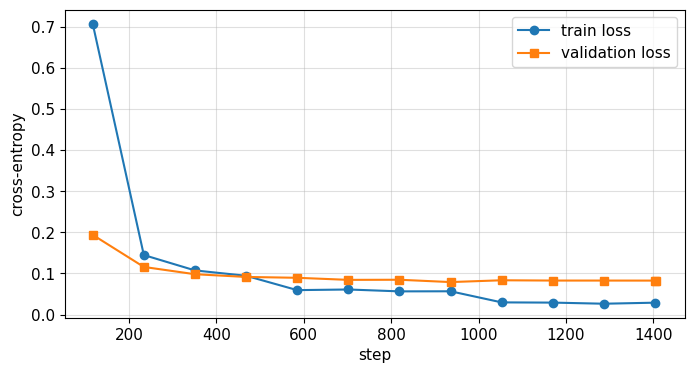

**Ответ 4.1.** AdamW, lr=0.0002, batch=32, epochs=3, warmup=10%, weight_decay=.01. Малый энкодер допускает больший lr, чем BERT-base; fp16 включён только на CUDA. Устройство Tesla T4, время 66.0 с. Validation loss: начало 0.1938, конец 0.0825, минимум 0.0789. Рост относительно минимума — повод проверить переобучение, один прогон не доказывает его причину.

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('runs/main/final/tokenizer_config.json', 'runs/main/final/tokenizer.json')

In [25]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(*zip(*train_curve), label='train'); ax.plot(*zip(*eval_curve), label='validation')
ax.legend(); ax.set(xlabel='Шаг оптимизации', ylabel='Cross-entropy loss', title='Обучение и валидация'); ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(ARTIFACTS/'learning_curves.png',dpi=150); plt.close(fig)
save_json('training_history.json', history)
answer('4.1', f'AdamW, lr={LR}, batch={BATCH_SIZE}, epochs={EPOCHS}, warmup=10%, weight_decay=.01. Малый энкодер допускает больший lr, чем BERT-base; fp16 включён только на CUDA. Устройство {DEVICE_NAME}, время {train_seconds:.1f} с. Validation loss: начало {eval_curve[0][1]:.4f}, конец {eval_curve[-1][1]:.4f}, минимум {min(v for _,v in eval_curve):.4f}. Рост относительно минимума — повод проверить переобучение, один прогон не доказывает его причину.')
model.save_pretrained('runs/main/final'); tokenizer.save_pretrained('runs/main/final')


**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ.** Использованы AdamW, learning rate 0,0002, batch 32, три эпохи, прогрев 10% шагов и weight decay 0,01. Batch 32 подошёл по памяти T4, прогрев смягчает первые обновления, weight decay регуляризует параметры. Validation loss снизился с 0,1938 до 0,0825 при минимуме 0,0789. Небольшой рост относительно минимума сам по себе не устанавливает переобучение. Для выбора числа эпох стоит сравнить контрольные точки по validation F1. Обучение заняло 66,0 с на Tesla T4.

## 4.2 Метрики

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [26]:
def token_f1(gold, pred):
    if len(gold) != len(pred): raise ValueError('sentence count mismatch')
    tp = ng = npred = 0
    for gs, ps in zip(gold,pred):
        if len(gs) != len(ps): raise ValueError('length mismatch')
        for g,p in zip(gs,ps):
            ng += g != 'O'; npred += p != 'O'; tp += p != 'O' and g == p
    return 2*tp/(ng+npred) if ng+npred else 0.0

In [27]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

def full_scores(gold, pred):
    result = entity_scores(gold, pred)
    report = classification_report(gold, pred, output_dict=True, zero_division=0)
    result.update(token_f1=token_f1(gold,pred), per_type={t:report[t] for t in ENTITY_TYPES if t in report})
    return result
val_pred = predict_word_tags(model, val_tokens)
validation = full_scores(val_gold, val_pred)
test_tokens = list(data['test']['tokens'])
test_gold = [[LABEL_NAMES[t] for t in ts] for ts in data['test']['ner_tags']]
test_pred = predict_word_tags(model, test_tokens)
final = full_scores(test_gold, test_pred)
for split,g,p in [('validation',val_gold,val_pred),('test',test_gold,test_pred)]:
    print(split); print(classification_report(g,p,digits=4,zero_division=0))
save_json('validation_metrics.json', validation)
min_type_f1 = min(final['per_type'][t]['f1-score'] for t in ENTITY_TYPES)
worst_types = [t for t in ENTITY_TYPES if abs(final['per_type'][t]['f1-score'] - min_type_f1)<1e-12]
worst_desc = ', '.join(worst_types) if len(worst_types)<len(ENTITY_TYPES) else 'все типы одновременно'
answer('4.2',
       f'Test: micro-F1={final["f1_micro"]:.4f}, macro-F1={final["f1_macro"]:.4f}, '
       f'precision={final["precision"]:.4f}, recall={final["recall"]:.4f}, '
       f'token-F1={final["token_f1"]:.4f}. Наиболее низкий F1: {worst_desc} ({min_type_f1:.4f}). '
       'Micro объединяет все истинные/ложные обнаружения, macro усредняет F1 по типам. '
       'Entity-F1 требует точного совпадения границ и типа, а token-F1 допускает частично правильные сущности. '
       'В случае почти нулевого F1 причина не может быть установлена только по метрике: исследуем предсказанные теги и число сущностей.')


validation
              precision    recall  f1-score   support

         LOC     0.8707    0.9049    0.8875      1525
        MISC     0.6562    0.6790    0.6674       461
         ORG     0.6911    0.6897    0.6904       464
         PER     0.8307    0.8543    0.8423       741

   micro avg     0.8050    0.8292    0.8169      3191
   macro avg     0.7622    0.7819    0.7719      3191
weighted avg     0.8043    0.8292    0.8165      3191

test
              precision    recall  f1-score   support

         LOC     0.8861    0.9144    0.9001      1566
        MISC     0.6641    0.6980    0.6806       490
         ORG     0.6624    0.6939    0.6778       526
         PER     0.8381    0.8724    0.8549       635

   micro avg     0.8056    0.8371    0.8210      3217
   macro avg     0.7627    0.7947    0.7784      3217
weighted avg     0.8063    0.8371    0.8214      3217



**Ответ 4.2.** Test: micro-F1=0.8210, macro-F1=0.7784, precision=0.8056, recall=0.8371, token-F1=0.8447. Наиболее низкий F1: ORG (0.6778). Micro объединяет все истинные/ложные обнаружения, macro усредняет F1 по типам. Entity-F1 требует точного совпадения границ и типа, а token-F1 допускает частично правильные сущности. В случае почти нулевого F1 причина не может быть установлена только по метрике: исследуем предсказанные теги и число сущностей.

### 4.2.1. Диагностика поведения NER на двух разбиениях

Сравниваем реальные и предсказанные типы слов, ошибки по тегам, а также F1 для каждого класса. Если модель предсказывает только `O`, это видно непосредственно на диаграммах. Гистограмма по словам **не заменяет** entity-level метрику: правильный тип слова ещё не означает корректно выделенную сущность.

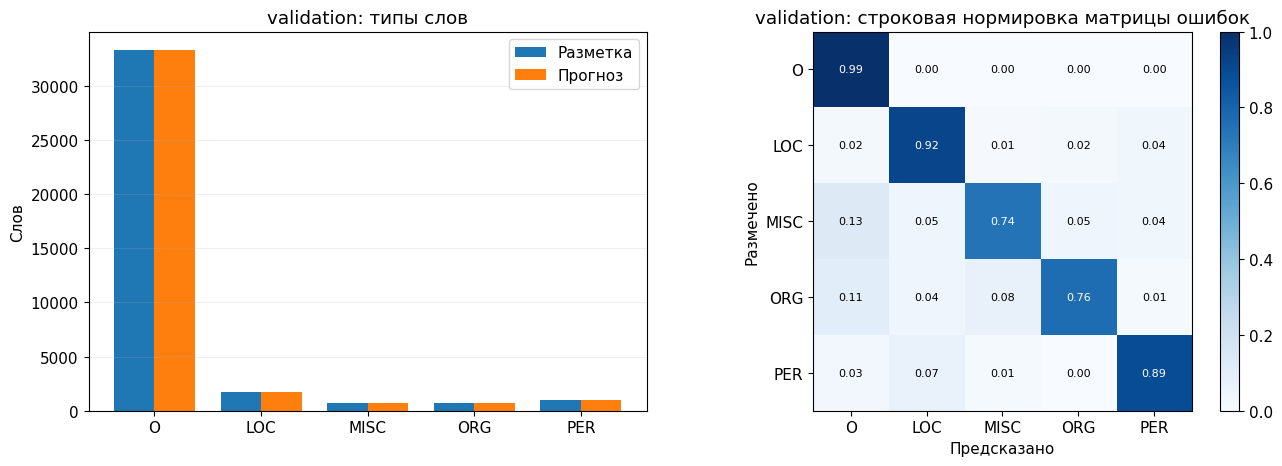

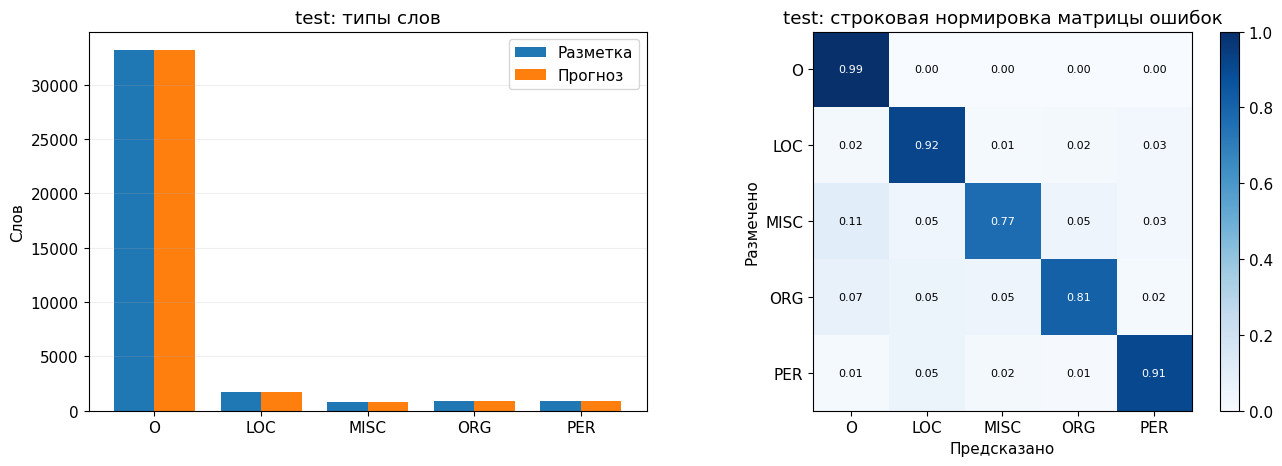

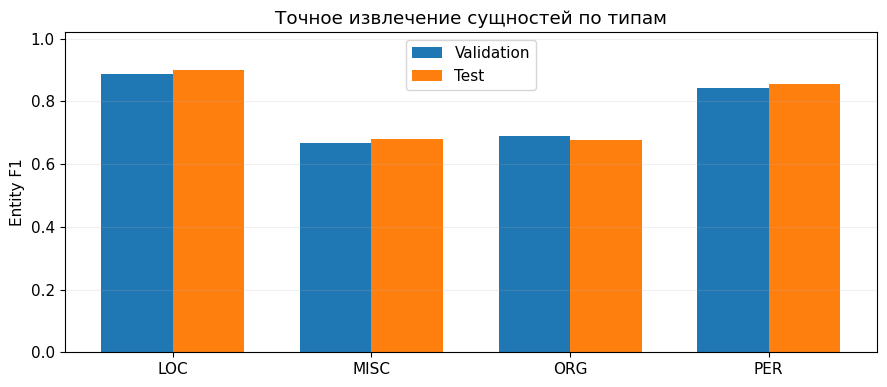

**Ответ 4.2-диагностика.** На validation модель выделила 4177 слов-сущностей при 4223 размеченных. Расхождение по количеству может означать избыток ложных выделений или пропуски; проверяем точные границы в анализе ошибок.

In [28]:
from IPython.display import display, Markdown

def short_type(tag):
    return 'O' if tag=='O' else tag.split('-',1)[-1]

def plot_predictions(gold, pred, split_name):
    assert len(gold)==len(pred)
    cats=['O']+ENTITY_TYPES
    flat_gold=[short_type(t) for ts in gold for t in ts]
    flat_pred=[short_type(t) for ts in pred for t in ts]
    assert len(flat_gold)==len(flat_pred)
    mat=np.zeros((len(cats),len(cats)),dtype=int)
    for g,p in zip(flat_gold,flat_pred): mat[cats.index(g),cats.index(p)]+=1
    gcount=collections.Counter(flat_gold); pcount=collections.Counter(flat_pred)
    fig,axes=plt.subplots(1,2,figsize=(13,4.8))
    z=np.arange(len(cats)); w=.38
    axes[0].bar(z-w/2,[gcount[k] for k in cats],w,label='Разметка')
    axes[0].bar(z+w/2,[pcount[k] for k in cats],w,label='Прогноз')
    axes[0].set_xticks(z,cats); axes[0].set_ylabel('Слов')
    axes[0].set_title(f'{split_name}: типы слов'); axes[0].legend()
    axes[0].grid(axis='y',alpha=.2)
    normalized=mat / np.maximum(mat.sum(axis=1,keepdims=True),1)
    im=axes[1].imshow(normalized,vmin=0,vmax=1,cmap='Blues')
    axes[1].set_xticks(z,cats); axes[1].set_yticks(z,cats)
    axes[1].set(xlabel='Предсказано',ylabel='Размечено',title=f'{split_name}: строковая нормировка матрицы ошибок')
    for ii in range(len(cats)):
        for jj in range(len(cats)):
            axes[1].text(jj,ii,f'{normalized[ii,jj]:.2f}',ha='center',va='center',
                         color='white' if normalized[ii,jj]>.55 else 'black',fontsize=8)
    fig.colorbar(im,ax=axes[1],fraction=.046)
    plt.tight_layout(); plt.savefig(ARTIFACTS/f'tag_diagnostics_{split_name}.png',dpi=150); plt.show()
    return {'gold_entities_words':int(len(flat_gold)-gcount['O']),
            'pred_entities_words':int(len(flat_pred)-pcount['O']),
            'pred_O_fraction':pcount['O']/max(len(flat_pred),1),
            'word_confusion':mat.tolist()}

tag_audit={'validation':plot_predictions(val_gold,val_pred,'validation'),
           'test':plot_predictions(test_gold,test_pred,'test')}
save_json('tag_diagnostics.json',tag_audit)
fig, ax=plt.subplots(figsize=(9,4))
classes=ENTITY_TYPES; ix=np.arange(len(classes)); bw=.36
ax.bar(ix-bw/2,[validation['per_type'][t]['f1-score'] for t in classes],bw,label='Validation')
ax.bar(ix+bw/2,[final['per_type'][t]['f1-score'] for t in classes],bw,label='Test')
ax.set_xticks(ix,classes); ax.set_ylim(0,1.02); ax.set_ylabel('Entity F1')
ax.set_title('Точное извлечение сущностей по типам'); ax.legend(); ax.grid(axis='y',alpha=.2)
plt.tight_layout(); plt.savefig(ARTIFACTS/'class_f1.png',dpi=150); plt.show()
if tag_audit['validation']['pred_entities_words']==0:
    explanation=('На validation модель не предсказала ни одного слова-сущности: все слова отнесены к O. '
                 'Это согласуется с нулевым entity-F1 и объясняет полностью пропущенные сущности. '
                 'Проверьте бюджет обучения, баланс меток и динамику loss; одной низкой loss недостаточно.')
else:
    explanation=(f'На validation модель выделила {tag_audit["validation"]["pred_entities_words"]} слов-сущностей '
                 f'при {tag_audit["validation"]["gold_entities_words"]} размеченных. '
                 'Расхождение по количеству может означать избыток ложных выделений или пропуски; '
                 'проверяем точные границы в анализе ошибок.')
answer('4.2-диагностика', explanation)


**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ.** На test entity micro-F1 = 0,8210, macro-F1 = 0,7784, precision = 0,8056, recall = 0,8371. По типам: LOC 0,9001, PER 0,8549, MISC 0,6806, ORG 0,6778. ORG имеет наименьший F1 и встречается в train реже LOC. Разнообразие названий организаций может влиять на качество, но вклад каждого фактора отдельно не измерялся. Micro объединяет сущности всех типов, macro одинаково взвешивает типы. Token F1 = 0,8447, потому что частичное совпадение может засчитываться по словам. Для извлечения целой сущности важнее entity F1.

---
# 5. Анализ

## 5.1 Разбор ошибок

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [29]:
ERROR_CATEGORIES = ['correct','boundary','type','missed','spurious']
def categorize_errors(gold_spans, pred_spans):
    def overlap(g,p): return max(g[0],p[0]) < min(g[1],p[1])
    result = []
    for g in gold_spans:
        exact = [p for p in pred_spans if tuple(p)==tuple(g)]
        same = [p for p in pred_spans if overlap(g,p) and p[2]==g[2]]
        other = [p for p in pred_spans if overlap(g,p)]
        candidates = exact or same or other
        cat = 'correct' if exact else 'boundary' if same else 'type' if other else 'missed'
        chosen = max(candidates,key=lambda p:min(g[1],p[1])-max(g[0],p[0])) if candidates else None
        result.append((cat,g,chosen))
    result.extend(('spurious',None,p) for p in pred_spans if not any(overlap(g,p) for g in gold_spans))
    return result

In [30]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

errors = {}   # ваш код: {категория: число} на validation, затем доли и 5+ примеров
counts = collections.Counter(); examples = collections.defaultdict(list)
for words,gs,ps in zip(val_tokens,val_gold,val_pred):
    for cat,g,p in categorize_errors(bio_to_spans(gs),bio_to_spans(ps)):
        counts[cat] += 1
        if cat != 'correct' and len(examples[cat]) < 5:
            examples[cat].append(dict(text=' '.join(words), gold=g, pred=p,
                gold_text=' '.join(words[g[0]:g[1]]) if g else None,
                pred_text=' '.join(words[p[0]:p[1]]) if p else None))
errors = {c:counts[c] for c in ERROR_CATEGORIES}
n_errors = sum(v for k,v in errors.items() if k!='correct')
shares = {k:v/max(n_errors,1) for k,v in errors.items() if k!='correct'}
print(json.dumps(dict(counts=errors,shares=shares,examples=examples),ensure_ascii=False,indent=2))
save_json('error_examples.json', dict(examples)); save_json('error_shares.json', shares)
common = max(shares,key=shares.get)
answer('5.1', f'Категории {errors}; доли среди ошибок {shares}. Самая частая: {common}. Примеры выше позволяют проверить полные и частичные имена. Boundary требует проверки границ, type — неоднозначных контекстов, missed — редких и обрезанных сущностей, spurious — обычных слов с заглавной буквой. Автоматическая разметка может ошибаться, но без ручной проверки конкретные расхождения не объявляем её ошибками. Для {common} сначала проверим примеры, затем добавим адресные данные; единица подсчёта следует контракту задания, не one-to-one matching.')

{
  "counts": {
    "correct": 2646,
    "boundary": 173,
    "type": 290,
    "missed": 82,
    "spurious": 118
  },
  "shares": {
    "boundary": 0.2609351432880845,
    "type": 0.4374057315233786,
    "missed": 0.12368024132730016,
    "spurious": 0.1779788838612368
  },
  "examples": {
    "spurious": [
      {
        "text": "8 февраля бойцы МПЛА при кубинской поддержке заняли важный стратегический город Санту-Антониу-ду-Заири .",
        "gold": null,
        "pred": [
          3,
          4,
          "ORG"
        ],
        "gold_text": null,
        "pred_text": "МПЛА"
      },
      {
        "text": "В марте 1922 года в Чурапче они учредили Временное якутское областное народное управление .",
        "gold": null,
        "pred": [
          8,
          13,
          "ORG"
        ],
        "gold_text": null,
        "pred_text": "Временное якутское областное народное управление"
      },
      {
        "text": "Когда пришло время идти в армию , перешёл в вологодское 

**Ответ 5.1.** Категории {'correct': 2646, 'boundary': 173, 'type': 290, 'missed': 82, 'spurious': 118}; доли среди ошибок {'boundary': 0.2609351432880845, 'type': 0.4374057315233786, 'missed': 0.12368024132730016, 'spurious': 0.1779788838612368}. Самая частая: type. Примеры выше позволяют проверить полные и частичные имена. Boundary требует проверки границ, type — неоднозначных контекстов, missed — редких и обрезанных сущностей, spurious — обычных слов с заглавной буквой. Автоматическая разметка может ошибаться, но без ручной проверки конкретные расхождения не объявляем её ошибками. Для type сначала проверим примеры, затем добавим адресные данные; единица подсчёта следует контракту задания, не one-to-one matching.

### 5.1.1. Диаграмма причин ошибок

Показываем раздельно правильные совпадения, ошибки границ, неверные типы, пропуски и ложные сущности. Категоризация отвечает процедуре выше и не претендует на оптимальное взаимно-однозначное сопоставление спанов.

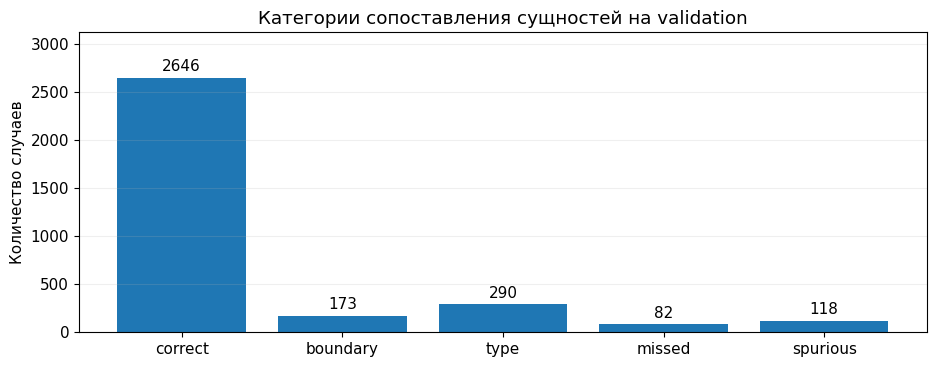

Примеры ошибок (не более трёх на категорию):
  boundary: 173
    Брокхауз стал профессором в университете Мак-Мастера в Канаде , где и оставался до пенсии в 1984 г . | разметка: университете Мак-Мастера | прогноз: Мак-Мастера
    23 декабря 2007 года подписал двухлетний контракт с новосибирской « Сибирью » , осуществив мечту играть за родной город . | разметка: Сибирью » | прогноз: »
    Хотя ранее сообщалось , что к футболисту проявлял пристальный интерес московский ЦСКА . | разметка: московский ЦСКА | прогноз: ЦСКА
  type: 290
    Хотя резиденция епископа Содора находилась на Мэне , его деятельность способствовала развитию церковной жизни на всех Гебридс | разметка: Содора | прогноз: Содора
    Вожди кри также соединяются с американскими экологическими группами и запускают общественную кампанию , критикующую проект Гр | разметка: Hydro-Québec | прогноз: Hydro-Québec
    С помощью орбитального телескопа Spitzer в системе удалось зарегистрировать диск из мелких частиц холодной пыли . |

In [31]:
fig,ax=plt.subplots(figsize=(9.5,3.8))
keys=ERROR_CATEGORIES
bars=ax.bar(keys,[errors[k] for k in keys])
ax.set_title('Категории сопоставления сущностей на validation')
ax.set_ylabel('Количество случаев')
for rect,key in zip(bars,keys):
    h=rect.get_height()
    ax.text(rect.get_x()+rect.get_width()/2,h+max(errors.values(),default=1)*.015,f'{h}',ha='center',va='bottom')
ax.set_ylim(0,max(1,max(errors.values(),default=0))*1.18)
ax.grid(axis='y',alpha=.2)
plt.tight_layout(); plt.savefig(ARTIFACTS/'error_categories.png',dpi=150); plt.show()
print('Примеры ошибок (не более трёх на категорию):')
for cat in ['boundary','type','missed','spurious']:
    print(f'  {cat}: {errors[cat]}')
    for ex in examples.get(cat,[])[:3]:
        print('   ',ex['text'][:125], '| разметка:',ex['gold_text'],'| прогноз:',ex['pred_text'])


**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ.** На validation найдено 2 646 точных совпадений. Среди 663 ошибок наиболее частая категория — неверный тип (290, 43,7%), далее границы (173), лишние сущности (118) и пропуски (82). При ошибке типа выделенный фрагмент пересекается с эталоном, но модель присваивает другой класс. Ошибки границ возникают при частичном выделении или захвате лишнего слова. Вручную стоит разобрать пары ORG/LOC и ORG/MISC и проверить спорные эталоны. По одному расхождению нельзя установить ошибку автоматической разметки.

### 5.1.2. Примеры ошибок на validation

Спаны взяты из сохранённого прогона. Прочерк обозначает отсутствие соответствующего спана.

| Категория | Предложение | Эталон | Предсказание | Разбор |
|---|---|---|---|---|
| boundary | Хотя ранее сообщалось , что к футболисту проявлял пристальный интерес московский ЦСКА . | **московский ЦСКА** (ORG) | **ЦСКА** (ORG) | Границы различаются при совпадающем типе. |
| boundary | Брокхауз стал профессором в университете Мак-Мастера в Канаде , где и оставался до пенсии в 1984 г . | **университете Мак-Мастера** (LOC) | **Мак-Мастера** (LOC) | Границы различаются при совпадающем типе. |
| type | Последнее из них было также аннулировано правительством Хуареса . | **Хуареса** (PER) | **Хуареса** (LOC) | Границы совпали или пересеклись, но присвоен другой тип. |
| missed | К травести относятся : в драматическом театре роли девушек , которым по ходу действия приходится выдавать себя за мужчин , переодеваться в мужское платье ( например , Виола в « Двенадцатой ночи » Шекспира , Шура Азарова в « Давным-давно » Александра Гладкова , Беатриче в « Слуге двух господ » Карло Гольдони , Габриэль в водевиле Ф. А. Кони « Девушка-гусар » , Тильтиль и Митиль в « Синей птице » Мориса Метерлинка ) , Вера Бендина , Евгения Морес , Зоя Булгакова , Нина Казаринова , К. П. Коренева , Мария Неменко-Бабковская , Александра Охитина , Валентина Сперантова , Мария Виноградова , Людмила Чернышёва . | **Давным-давно** (MISC) | — | С эталонной сущностью не пересекается ни один предсказанный спан. |
| spurious | Виккерс использовался как французской , так и русской авиацией . | — | **французской** (MISC) | Предсказанный спан не пересекается с эталонной сущностью. |

Среди 663 ошибок наиболее частая категория — неверный тип (290, 43,7%). Для этой категории стоит отдельно проверить пары типов и качество исходной разметки.


## 5.2 Абляция

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [32]:
ABLATION = 'freeze'
model.cpu()
set_seed(SEED)
abl_model = make_model()
abl_history, abl_seconds = train_ner(abl_model, tokenized['train'], tokenized['validation'], freeze_encoder=True, out_dir='runs/freeze')
abl_scores = full_scores(val_gold, predict_word_tags(abl_model,val_tokens))
ablation = dict(setting=ABLATION, split='validation',
    full=dict(metrics=validation, seconds=train_seconds, trainable=sum(p.numel() for p in model.parameters() if p.requires_grad)),
    frozen=dict(metrics=abl_scores, seconds=abl_seconds, trainable=sum(p.numel() for p in abl_model.parameters() if p.requires_grad)))
del abl_model
if device.type=='cuda': torch.cuda.empty_cache()
answer('5.2', f'Полное обучение: F1={validation["f1_micro"]:.4f}, {train_seconds:.1f} с; frozen: F1={abl_scores["f1_micro"]:.4f}, {abl_seconds:.1f} с. Обучаемых параметров {ablation["full"]["trainable"]:,} и {ablation["frozen"]["trainable"]:,}. Заморозка исключает адаптацию контекстных признаков. Одинаковые seed, данные, эпохи и lr; это контролируемая абляция, а не поиск лучшего lr для frozen. Надёжность проверить на нескольких seed.')


Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Step,Training Loss,Validation Loss
117,1.754554,1.116764
234,0.638015,0.419714
351,0.373027,0.337898
468,0.311472,0.299857
585,0.292657,0.275436
702,0.276250,0.259335
819,0.262214,0.247958
936,0.252394,0.239765
1053,0.243923,0.234080
1170,0.241879,0.230292


**Ответ 5.2.** Полное обучение: F1=0.8169, 66.0 с; frozen: F1=0.5229, 33.6 с. Обучаемых параметров 29,098,929 и 2,817. Заморозка исключает адаптацию контекстных признаков. Одинаковые seed, данные, эпохи и lr; это контролируемая абляция, а не поиск лучшего lr для frozen. Надёжность проверить на нескольких seed.

### 5.2.1. Сравнение baseline, fine-tuning и абляции

Метрики рассчитываются на одном и том же validation. Низкая или нулевая оценка любой модели не должна описываться как улучшение. Время сравнимо между двумя режимами обучения, а не со словарём, для которого здесь время не измеряли.

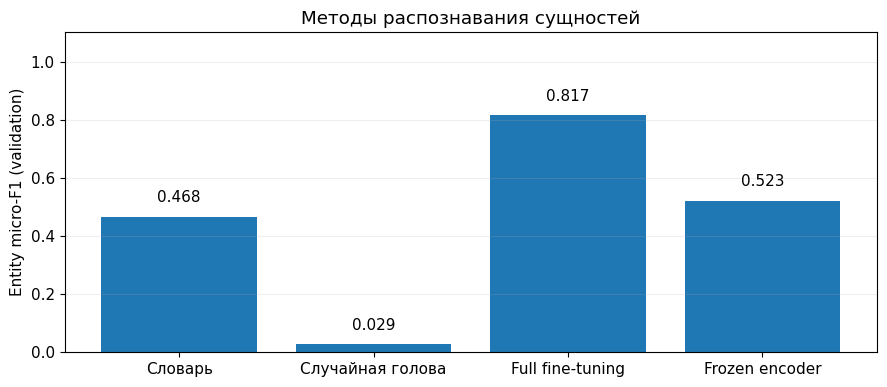

Полное обучение: 66.0 с; замороженный энкодер: 33.6 с; разница F1 (full - freeze) = +0.2940.


In [33]:
methods=['Словарь','Случайная голова','Full fine-tuning','Frozen encoder']
f1_values=[baseline['majority']['f1_micro'],baseline['random_head']['f1_micro'],
           validation['f1_micro'],abl_scores['f1_micro']]
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(methods,f1_values)
ax.set_ylim(0,max(.1,max(f1_values)*1.35))
ax.set_ylabel('Entity micro-F1 (validation)');ax.set_title('Методы распознавания сущностей')
for j,v in enumerate(f1_values):ax.text(j,v+max(.012,max(f1_values)*.06),f'{v:.3f}',ha='center')
ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.savefig(ARTIFACTS/'model_comparison.png',dpi=150);plt.show()
print(f'Полное обучение: {train_seconds:.1f} с; замороженный энкодер: {abl_seconds:.1f} с; '
      f'разница F1 (full - freeze) = {validation["f1_micro"]-abl_scores["f1_micro"]:+.4f}.')


**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ.** При заморозке энкодера validation micro-F1 снизился с 0,8169 до 0,5229, время обучения — с 66,0 до 33,6 с. Обучалось 2 817 параметров головы вместо 29 098 929 параметров модели. Заморозка ограничивает адаптацию представлений к NER. Для проверки устойчивости результата нужны повторы с несколькими seed и отдельный подбор learning rate для головы.

## 5.3 Выводы

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ.** RuBERT-tiny2 обучена на 15 000 предложениях. На validation micro-F1 составил 0,8169 против 0,4677 у словаря. На test entity micro-F1 равен 0,8210, macro-F1 — 0,7784. Заморозка энкодера снизила validation micro-F1 до 0,5229. Самая частая категория ошибок на validation — неверный тип сущности. Выводы ограничены автоматической разметкой WikiNEuRal, доменом Wikipedia, длиной входа 128 и одним seed. Следующий эксперимент — повторение на нескольких seed и проверка на независимо размеченных текстах.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [34]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))
answer('5.3', f'Основная модель {MODEL_ID} обучена на {len(data["train"])} предложениях. Test entity F1={final["f1_micro"]:.4f}, macro F1={final["f1_macro"]:.4f}. На validation F1={validation["f1_micro"]:.4f} против словаря {baseline["majority"]["f1_micro"]:.4f}. Token F1 на test равен {final["token_f1"]:.4f}. Обучение заняло {train_seconds:.1f} с на {DEVICE_NAME}. В абляции frozen validation F1={abl_scores["f1_micro"]:.4f}: знак сравнения определяет результат, преимущество full fine-tuning не предполагается. Ограничения: автоматическая разметка, Wikipedia-домен, подмножества и MAX_LENGTH={MAX_LENGTH}. Следующие шаги — несколько seed, ручная проверка ошибок и оценка на независимом новостном корпусе.')


{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "Babelscape/wikineural", "classes": ["LOC", "MISC", "ORG", "PER"], "n_train": 15000, "n_val": 2000, "n_test": 2000, "params_total": 29098929, "ablation": {"setting": "freeze", "split": "validation", "full": {"metrics": {"f1_micro": 0.8169188020994134, "f1_macro": 0.7718879280142983, "precision": 0.8049893519926985, "recall": 0.8292071450955814, "token_f1": 0.8335714285714285, "per_type": {"LOC": {"precision": 0.8706624605678234, "recall": 0.9049180327868852, "f1-score": 0.8
final F1 micro 0.821


**Ответ 5.3.** Основная модель cointegrated/rubert-tiny2 обучена на 15000 предложениях. Test entity F1=0.8210, macro F1=0.7784. На validation F1=0.8169 против словаря 0.4677. Token F1 на test равен 0.8447. Обучение заняло 66.0 с на Tesla T4. В абляции frozen validation F1=0.5229: знак сравнения определяет результат, преимущество full fine-tuning не предполагается. Ограничения: автоматическая разметка, Wikipedia-домен, подмножества и MAX_LENGTH=128. Следующие шаги — несколько seed, ручная проверка ошибок и оценка на независимом новостном корпусе.

## 6. Дополнительные эксперименты

### 6.1 Дополнительный набор

Для оценки на отдельной выборке загрузите в рабочую папку Colab файл `extra_ner.jsonl`. В каждой строке укажите `tokens` (список слов) и `spans` (начало, конец без включения и тип сущности).

In [35]:
import shutil

if '6.1' in BONUS_TASKS:
    extra_path = Path('extra_ner.jsonl')
    if not extra_path.is_file():
        BONUS_RESULTS['6.1'] = {'status': 'missing_dataset'}
        answer('6.1', 'Файл extra_ner.jsonl отсутствует: оценка на вручную размеченной независимой выборке не проведена. Нельзя подменять её WikiNEuRal test.')
    else:
        rows = [json.loads(line) for line in extra_path.read_text(encoding='utf-8').splitlines() if line.strip()]
        assert len(rows) >= 50, 'Нужно не менее 50 предложений'
        extra_tokens = [row['tokens'] for row in rows]
        keys = [tuple(words) for words in extra_tokens]
        assert len(set(keys)) == len(keys), 'В дополнительном наборе есть дубликаты'
        assert not set(keys).intersection(seen), 'Дополнительный набор пересекается с WikiNEuRal'
        extra_gold = []
        for row in rows:
            spans = [tuple(span) for span in row['spans']]
            assert all(label in ENTITY_TYPES for _, _, label in spans), 'Неизвестный тип сущности'
            extra_gold.append(spans_to_bio(spans, len(row['tokens'])))
        extra_scores = full_scores(extra_gold, predict_word_tags(model, extra_tokens))
        BONUS_RESULTS['6.1'] = dict(n=len(rows), original_test=final, extra_test=extra_scores)
        shutil.copy(extra_path, ARTIFACTS / extra_path.name)
        answer('6.1', f'Дополнительная выборка: {len(rows)} предложений, micro-F1={extra_scores["f1_micro"]:.4f}. '
                      f'WikiNEuRal test: micro-F1={final["f1_micro"]:.4f}. '
                      'Разница характеризует качество на разных выборках.')


**Ответ 6.1.** Файл extra_ner.jsonl отсутствует: оценка на вручную размеченной независимой выборке не проведена. Нельзя подменять её WikiNEuRal test.

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ.** Дополнительный эксперимент не выполнен: файл с 50+ самостоятельно размеченными предложениями отсутствует. В результатах сохранён статус `missing_dataset`.

## 6.2 Другая модель

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [36]:
def benchmark_ner(m,tok,words,dev,repeat=20):
    m.to(dev).eval()
    batch = tok(words,is_split_into_words=True,padding='max_length',truncation=True,max_length=MAX_LENGTH,return_tensors='pt')
    batch = {k:v.to(dev) for k,v in batch.items()}
    with torch.inference_mode():
        for _ in range(5): m(**batch)
        if str(dev).startswith('cuda'): torch.cuda.synchronize()
        start = time.perf_counter()
        for _ in range(repeat): m(**batch)
        if str(dev).startswith('cuda'): torch.cuda.synchronize()
    return (time.perf_counter()-start)*1000/repeat

if '6.2' in BONUS_TASKS:
    import gc
    ALT_MODEL_ID = 'cointegrated/rubert-tiny'
    ALT_REVISION = locked_revision(ALT_MODEL_ID)
    alt_tok = AutoTokenizer.from_pretrained(ALT_MODEL_ID,revision=ALT_REVISION)
    alt_tokenized = data.map(lambda b:tokenize_and_align(b,tok=alt_tok),batched=True,remove_columns=data['train'].column_names)
    model.cpu(); gc.collect()
    if device.type=='cuda': torch.cuda.empty_cache()
    set_seed(SEED)
    alt_model = make_model(ALT_MODEL_ID,ALT_REVISION)
    alt_history, alt_seconds = train_ner(alt_model,alt_tokenized['train'],alt_tokenized['validation'],tok=alt_tok,out_dir='runs/alternative')
    alt_scores = full_scores(val_gold,predict_word_tags(alt_model,val_tokens,tok=alt_tok))
    words = val_tokens[:8]
    alt_ms = benchmark_ner(alt_model,alt_tok,words,device)
    alt_params = sum(p.numel() for p in alt_model.parameters())
    alt_model.cpu()
    main_ms = benchmark_ner(model,tokenizer,words,device)
    BONUS_RESULTS['6.2'] = dict(model=ALT_MODEL_ID,revision=ALT_REVISION,metrics=alt_scores,train_seconds=alt_seconds,
        params=alt_params,main_params=sum(p.numel() for p in model.parameters()),main_ms=main_ms,alternative_ms=alt_ms,
        batch=len(words),padded_length=MAX_LENGTH,device=DEVICE_NAME)
    answer('6.2', f'Validation F1 основной={validation["f1_micro"]:.4f}, альтернативы={alt_scores["f1_micro"]:.4f}; обучение {train_seconds:.1f} / {alt_seconds:.1f} с. Параметры {sum(p.numel() for p in model.parameters()):,} / {alt_params:,}. Forward batch {len(words)} x {MAX_LENGTH}: {main_ms:.2f} / {alt_ms:.2f} мс. Одни сплиты, seed, эпохи, lr и устройство; токенизаторы соответствуют моделям. Сравнение качества — validation; одинаковый lr контролирует условия, но может быть неоптимален для каждой модели. При равенстве нулевых F1 победителя по качеству нет.')
    del alt_model; gc.collect()


config.json:   0%|          | 0.00/632 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/341 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/241k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/468k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/15000 [00:00<?, ? examples/s]

... (3 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Step,Training Loss,Validation Loss
117,0.746510,0.192508
234,0.151187,0.117266
351,0.114222,0.104265
468,0.101810,0.096286
585,0.073697,0.095419
702,0.073591,0.090875
819,0.067469,0.089011
936,0.067743,0.087132
1053,0.044387,0.088809
1170,0.042890,0.088869


**Ответ 6.2.** Validation F1 основной=0.8169, альтернативы=0.7896; обучение 66.0 / 55.8 с. Параметры 29,098,929 / 11,689,329. Forward batch 8 x 128: 4.56 / 4.29 мс. Одни сплиты, seed, эпохи, lr и устройство; токенизаторы соответствуют моделям. Сравнение качества — validation; одинаковый lr контролирует условия, но может быть неоптимален для каждой модели. При равенстве нулевых F1 победителя по качеству нет.

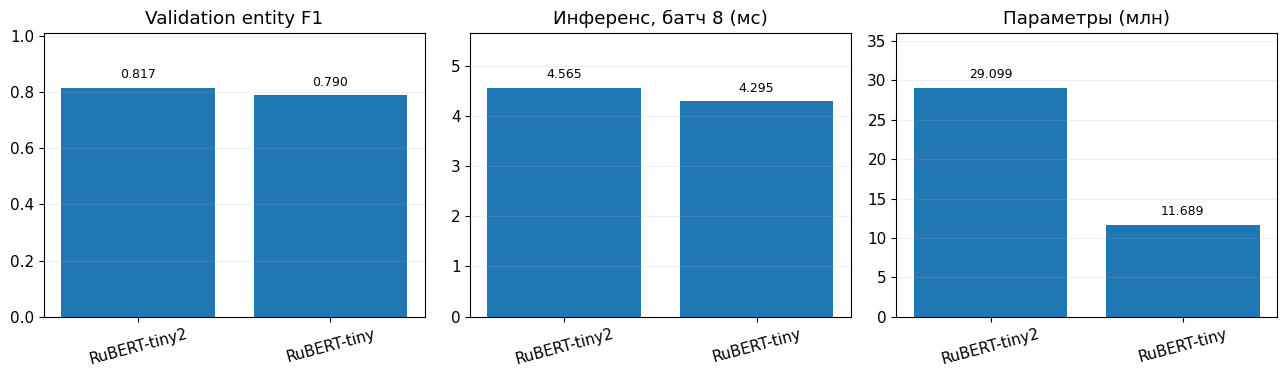

По entity F1 на этом validation лучше основная модель; сравнение на одном seed ограничено.


In [37]:
if '6.2' in BONUS_RESULTS:
    b=BONUS_RESULTS['6.2']; names=['RuBERT-tiny2','RuBERT-tiny']
    fig,axes=plt.subplots(1,3,figsize=(13,3.9))
    panels=[([validation['f1_micro'],b['metrics']['f1_micro']],'Validation entity F1',''),
            ([b['main_ms'],b['alternative_ms']],'Инференс, батч 8 (мс)','мс'),
            ([b['main_params']/1e6,b['params']/1e6],'Параметры (млн)','млн')]
    for ax,(vals,title,unit) in zip(axes,panels):
        ax.bar(names, vals); ax.set_title(title); ax.tick_params(axis='x',rotation=15)
        ax.grid(axis='y',alpha=.2)
        for k,v in enumerate(vals):ax.text(k,v+max(.01,max(vals)*.04),f'{v:.3f}',ha='center',fontsize=9)
        ax.set_ylim(0,max(.1,max(vals)*1.24))
    plt.tight_layout();plt.savefig(ARTIFACTS/'alternative_model.png',dpi=150);plt.show()
    if validation['f1_micro']==0 and b['metrics']['f1_micro']==0:
        print('Обе модели имеют нулевой F1: сравнивать, какая из них лучше распознаёт сущности, пока нельзя.')
    else:
        better='основная' if validation['f1_micro']>b['metrics']['f1_micro'] else 'альтернативная'
        print(f'По entity F1 на этом validation лучше {better} модель; сравнение на одном seed ограничено.')


**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ.** На validation RuBERT-tiny2 получила micro-F1 0,8169 против 0,7896 у RuBERT-tiny. У моделей 29,1 и 11,7 млн параметров, обучение заняло 66,0 и 55,8 с. Задержка прямого прохода — 4,56 и 4,29 мс на одинаковом батче на T4. Сплиты, seed, эпохи и learning rate одинаковы. Число параметров характеризует размер моделей, пик потребления памяти отдельно не измерялся.

## 6.3 Устойчивость к сдвигу

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [38]:
if '6.3' in BONUS_TASKS:
    def typo_word(w):
        return w[:1]+w[2:3]+w[1:2]+w[3:] if len(w)>4 else w
    variants = {'lower':[[w.lower() for w in ws] for ws in val_tokens],
                'upper':[[w.upper() for w in ws] for ws in val_tokens],
                'typos':[[typo_word(w) for w in ws] for ws in val_tokens]}
    shifts = {name:full_scores(val_gold,predict_word_tags(model,ws)) for name,ws in variants.items()}
    BONUS_RESULTS['6.3'] = shifts
    drops={name:validation['f1_micro']-score['f1_micro'] for name,score in shifts.items()}
    positive_drops={k:v for k,v in drops.items() if v>1e-12}
    shift_conclusion=(f'Наиболее сильное снижение: {max(positive_drops,key=positive_drops.get)}, '
                      f'дельта F1={max(positive_drops.values()):.4f}.' if positive_drops else
                      'Измеримого снижения F1 нет; при нулевом исходном F1 устойчивость оценить нельзя.')
    answer('6.3', f'Исходный F1={validation["f1_micro"]:.4f}; сдвиги: '+str({k:round(v['f1_micro'],4) for k,v in shifts.items()})+f'. {shift_conclusion} Регистр меняет сигнал имени собственного, опечатки меняют сабворды; число слов и метки сохраняются, но изменение семантики — ограничение синтетической порчи.')


**Ответ 6.3.** Исходный F1=0.8169; сдвиги: {'lower': np.float64(0.1843), 'upper': np.float64(0.0362), 'typos': np.float64(0.5905)}. Наиболее сильное снижение: upper, дельта F1=0.7807. Регистр меняет сигнал имени собственного, опечатки меняют сабворды; число слов и метки сохраняются, но изменение семантики — ограничение синтетической порчи.

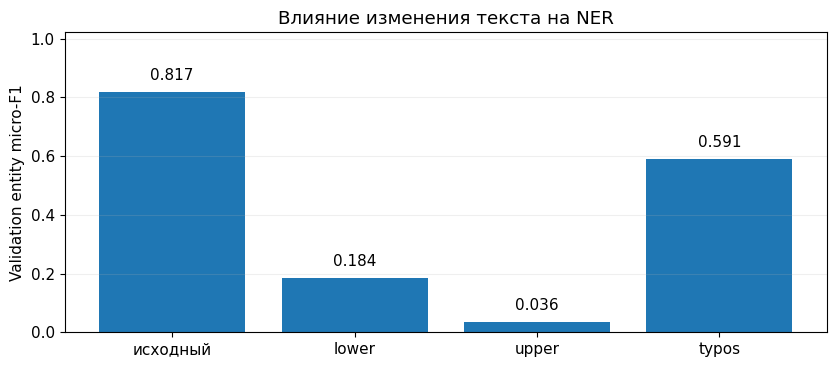

Наиболее сильное снижение: upper, дельта F1=0.7807.


In [39]:
if '6.3' in BONUS_RESULTS:
    names=['исходный']+list(shifts)
    vals=[validation['f1_micro']]+[shifts[k]['f1_micro'] for k in shifts]
    fig,ax=plt.subplots(figsize=(8.5,3.8))
    ax.bar(names,vals)
    ax.set_ylabel('Validation entity micro-F1');ax.set_title('Влияние изменения текста на NER')
    ax.set_ylim(0,max(.1,max(vals)*1.25));ax.grid(axis='y',alpha=.2)
    for i,v in enumerate(vals):ax.text(i,v+max(.007,max(vals)*.05),f'{v:.3f}',ha='center')
    plt.tight_layout();plt.savefig(ARTIFACTS/'text_shift.png',dpi=150);plt.show()
    print(shift_conclusion)


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ.** На validation micro-F1 снизился с 0,8169 до 0,1843 при нижнем регистре, до 0,0362 при верхнем и до 0,5905 при опечатках. Сильнее всего повлиял верхний регистр. Изменение регистра убирает привычные признаки написания имён и может менять разбиение на сабворды. Опечатки тоже меняют сабворды и делают формы слов менее знакомыми.

## 6.4 Экспорт и скорость

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [40]:
if '6.4' in BONUS_TASKS:
    # Динамическая INT8-квантизация Linear на CPU; GPU и CPU скорости не смешиваем.
    import io, gc
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    cpu_model = copy.deepcopy(model).cpu().eval()
    # API остается рабочим в зафиксированной среде, но официально устаревает.
    # Сохраняем его для воспроизводимости эксперимента; для нового продакшен-кода нужен torchao.
    import warnings
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='.*torch.ao.quantization is deprecated.*', category=DeprecationWarning)
        qmodel = torch.ao.quantization.quantize_dynamic(cpu_model,{torch.nn.Linear},dtype=torch.qint8,inplace=False)
    words = val_tokens[:8]
    cpu_ms = benchmark_ner(cpu_model,tokenizer,words,torch.device('cpu'))
    int8_ms = benchmark_ner(qmodel,tokenizer,words,torch.device('cpu'))
    cpu_pred = predict_word_tags(cpu_model,val_tokens,batch_size=32,dev=torch.device('cpu'))
    qpred = predict_word_tags(qmodel,val_tokens,batch_size=32,dev=torch.device('cpu'))
    cpu_scores, q_scores = full_scores(val_gold,cpu_pred),full_scores(val_gold,qpred)
    def serialized_bytes(m):
        buf=io.BytesIO(); torch.save(m.state_dict(),buf); return buf.tell()
    BONUS_RESULTS['6.4'] = dict(device='cpu',threads=torch.get_num_threads(),fp32_ms=cpu_ms,int8_ms=int8_ms,
        speedup=cpu_ms/int8_ms,fp32_metrics=cpu_scores,int8_metrics=q_scores,
        fp32_bytes=serialized_bytes(cpu_model),int8_bytes=serialized_bytes(qmodel))
    answer('6.4', f'CPU FP32={cpu_ms:.2f} мс, INT8={int8_ms:.2f} мс, отношение={cpu_ms/int8_ms:.2f}x. F1={cpu_scores["f1_micro"]:.4f} / {q_scores["f1_micro"]:.4f}. Одинаковые batch, длина, потоки, устройство, 5 прогревов и 20 повторов; квантизированы Linear, эмбеддинги остаются FP32. Ускорение не гарантировано: маленькая модель и преобразования активаций могут нивелировать выигрыш. Сравнение выполняется на всём выбранном validation. При F1=0 для обеих моделей нельзя утверждать сохранение способности распознавать сущности.')
    del cpu_model,qmodel; gc.collect()


**Ответ 6.4.** CPU FP32=61.66 мс, INT8=56.31 мс, отношение=1.09x. F1=0.8169 / 0.8164. Одинаковые batch, длина, потоки, устройство, 5 прогревов и 20 повторов; квантизированы Linear, эмбеддинги остаются FP32. Ускорение не гарантировано: маленькая модель и преобразования активаций могут нивелировать выигрыш. Сравнение выполняется на всём выбранном validation. При F1=0 для обеих моделей нельзя утверждать сохранение способности распознавать сущности.

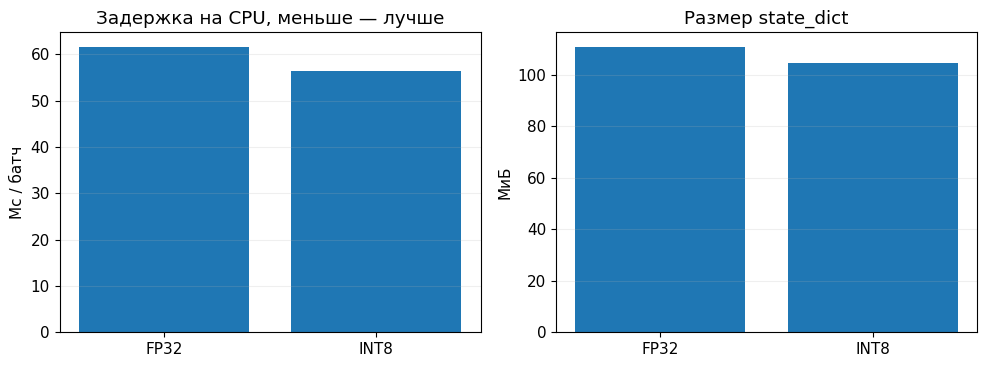

Ускорение CPU-инференса: 1.09x; изменение F1: -0.0005.


In [41]:
if '6.4' in BONUS_RESULTS:
    b=BONUS_RESULTS['6.4']
    fig,axes=plt.subplots(1,2,figsize=(10,3.8))
    axes[0].bar(['FP32','INT8'],[b['fp32_ms'],b['int8_ms']])
    axes[0].set_title('Задержка на CPU, меньше — лучше');axes[0].set_ylabel('Мс / батч')
    axes[1].bar(['FP32','INT8'],[b['fp32_bytes']/2**20,b['int8_bytes']/2**20])
    axes[1].set_title('Размер state_dict');axes[1].set_ylabel('МиБ')
    for ax in axes:ax.grid(axis='y',alpha=.2)
    plt.tight_layout();plt.savefig(ARTIFACTS/'quantization_benchmark.png',dpi=150);plt.show()
    print(f'Ускорение CPU-инференса: {b["speedup"]:.2f}x; '
          f'изменение F1: {b["int8_metrics"]["f1_micro"]-b["fp32_metrics"]["f1_micro"]:+.4f}.')


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ.** На CPU задержка снизилась с 61,66 мс в FP32 до 56,31 мс в INT8, ускорение 1,09×. Validation micro-F1 изменился с 0,8169 до 0,8164. Квантизированы линейные слои, а таблица эмбеддингов, в которой находится основная часть параметров, остаётся FP32.

## 6.5 Порог уверенности спана

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

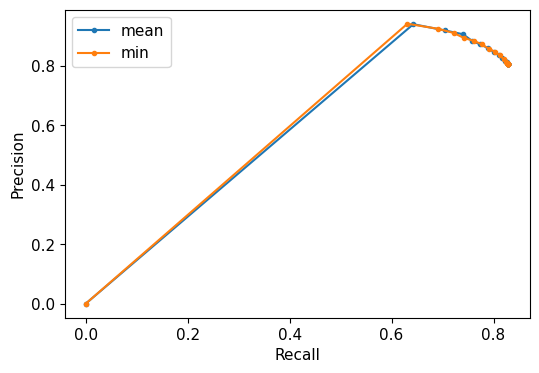

**Ответ 6.5.** Лучший mean-порог на validation=0.60, F1=0.8240, прирост к нулевому=0.0071. На test с уже фиксированным порогом F1=0.8315. При нулевом F1 на всех порогах оптимизация неинформативна; min чувствителен к одному неуверенному слову, mean сглаживает его. Удаление целых спанов не создаёт новых TP и не может увеличить recall; precision может и снизиться, если удаляются верные спаны.

In [42]:
if '6.5' in BONUS_TASKS:
    tags, probs = predict_word_tags(model,val_tokens,return_probs=True)
    def filter_spans(tags, probs, threshold, aggregation='mean'):
        result=[]
        for ts, pr in zip(tags,probs):
            spans=[s for s in bio_to_spans(ts) if (np.mean(pr[s[0]:s[1]]) if aggregation=='mean' else min(pr[s[0]:s[1]])) >= threshold]
            result.append(spans_to_bio(spans,len(ts)))
        return result
    curves={}
    plt.figure(figsize=(6,4))
    for mode in ['mean','min']:
        rows=[]
        for threshold in np.linspace(0,1,21):
            score=entity_scores(val_gold,filter_spans(tags,probs,threshold,mode))
            rows.append(dict(threshold=float(threshold),**score))
        curves[mode]=rows
        plt.plot([x['recall'] for x in rows],[x['precision'] for x in rows],'.-',label=mode)
    plt.xlabel('Recall'); plt.ylabel('Precision'); plt.legend(); plt.savefig(ARTIFACTS/'span_pr.png'); plt.show()
    best_threshold = max(curves['mean'],key=lambda x:(x['f1_micro'],-x['threshold']))
    test_tags,test_probs = predict_word_tags(model,test_tokens,return_probs=True)
    threshold_test=full_scores(test_gold,filter_spans(test_tags,test_probs,best_threshold['threshold'],'mean'))
    BONUS_RESULTS['6.5']=dict(curves=curves,selected_on_validation=best_threshold,test=threshold_test)
    answer('6.5', f'Лучший mean-порог на validation={best_threshold["threshold"]:.2f}, F1={best_threshold["f1_micro"]:.4f}, прирост к нулевому={best_threshold["f1_micro"]-curves["mean"][0]["f1_micro"]:.4f}. На test с уже фиксированным порогом F1={threshold_test["f1_micro"]:.4f}. При нулевом F1 на всех порогах оптимизация неинформативна; min чувствителен к одному неуверенному слову, mean сглаживает его. Удаление целых спанов не создаёт новых TP и не может увеличить recall; precision может и снизиться, если удаляются верные спаны.')


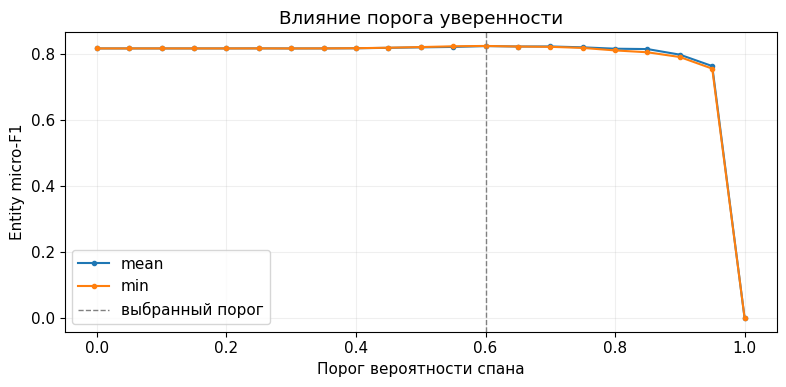

Оптимальный порог найден по validation: 0.60; F1 на test после фиксации порога: 0.8315.


In [43]:
if '6.5' in BONUS_RESULTS:
    fig,ax=plt.subplots(figsize=(8,4))
    for mode,rows in curves.items():
        ax.plot([r['threshold'] for r in rows],[r['f1_micro'] for r in rows],'.-',label=mode)
    ax.axvline(best_threshold['threshold'],ls='--',lw=1,color='gray',label='выбранный порог')
    ax.set(xlabel='Порог вероятности спана',ylabel='Entity micro-F1',title='Влияние порога уверенности')
    ax.legend();ax.grid(alpha=.2)
    plt.tight_layout();plt.savefig(ARTIFACTS/'threshold_f1.png',dpi=150);plt.show()
    if max(r['f1_micro'] for r in curves['mean'])==0:
        print('Невозможно выбрать содержательный порог: для всех порогов F1=0. Нужна обученная модель.')
    else:
        print(f'Оптимальный порог найден по validation: {best_threshold["threshold"]:.2f}; '
              f'F1 на test после фиксации порога: {threshold_test["f1_micro"]:.4f}.')


## 7. Сводные результаты и интерпретация

Таблица и итоговый вывод ниже автоматически формируются после выполнения кода. Не подставляйте результаты другого режима запуска: ограниченный FAST-прогон нужен прежде всего для диагностики, а окончательные выводы об обученной модели делаются после `FAST_MODE=False`.

In [44]:
from IPython.display import display, Markdown

report_lines=[
    '# Итоговый отчёт по NLP / NER',
    f'**Режим:** {"FAST — диагностический" if FAST_MODE else "полный"}. '
    f'**Устройство:** {DEVICE_NAME}. **Seed:** {SEED}.',
    f'**Данные:** {DATASET_ID}, train/validation/test = '
    f'{len(data["train"])}/{len(data["validation"])}/{len(data["test"])}.',
    f'**Обучение:** {MODEL_ID}, {EPOCHS} эпох, batch {BATCH_SIZE}, learning rate {LR:g}, '
    f'{train_seconds:.1f} с.',
    '',
    '### Основные метрики',
    '| Модель и разбиение | Entity micro-F1 | Precision | Recall |',
    '|:--|--:|--:|--:|',
]
for name,r in [('Словарный baseline (validation)',baseline['majority']),
               ('Random head (validation)',baseline['random_head']),
               ('Fine-tuned (validation)',validation),('Frozen (validation)',abl_scores),
               ('Fine-tuned (test)',final)]:
    report_lines.append(f'| {name} | {r["f1_micro"]:.4f} | {r["precision"]:.4f} | {r["recall"]:.4f} |')
report_lines += [
    '',
    f'По типам на test: '+', '.join(f'{t} = {final["per_type"][t]["f1-score"]:.4f}' for t in ENTITY_TYPES)+'.',
    f'Прогнозы на validation: {tag_audit["validation"]["pred_entities_words"]} слов-сущностей '
    f'из {tag_audit["validation"]["gold_entities_words"]} размеченных; '
    f'доля предсказанных O = {tag_audit["validation"]["pred_O_fraction"]:.1%}.',
    '', '### Разбор ошибок',
    'Категории: '+', '.join(f'{k}={errors[k]}' for k in ERROR_CATEGORIES)+'.',
    'Используется сравнение границ и типов спанов; в сомнительных случаях требуется анализ текста и разметки.',
    '', '### Абляция',
    f'Frozen encoder: F1={abl_scores["f1_micro"]:.4f} против '
    f'{validation["f1_micro"]:.4f} у full fine-tuning; '
    f'время {abl_seconds:.1f} против {train_seconds:.1f} с. '
    'Один seed не позволяет оценить разброс между обучениями.',
]
if '6.2' in BONUS_RESULTS:
    m=BONUS_RESULTS['6.2']
    report_lines.append(f'### Сравнение энкодеров\n'
         f'RuBERT-tiny2 F1={validation["f1_micro"]:.4f}, RuBERT-tiny F1={m["metrics"]["f1_micro"]:.4f}; '
         f'задержка на {DEVICE_NAME}: {m["main_ms"]:.2f} / {m["alternative_ms"]:.2f} мс.')
if '6.3' in BONUS_RESULTS:
    report_lines.append('### Сдвиг данных\n'
        +', '.join(f'{k}: F1={v["f1_micro"]:.4f}' for k,v in shifts.items())+'. '+shift_conclusion)
if '6.4' in BONUS_RESULTS:
    b=BONUS_RESULTS['6.4']
    report_lines.append(f'### Квантизация\n'
         f'CPU FP32/INT8: {b["fp32_ms"]:.2f}/{b["int8_ms"]:.2f} мс, '
         f'отношение {b["speedup"]:.2f}x; F1 {b["fp32_metrics"]["f1_micro"]:.4f}/'
         f'{b["int8_metrics"]["f1_micro"]:.4f}.')
if '6.5' in BONUS_RESULTS:
    report_lines.append(f'### Порог спана\n'
        f'Выбран по validation: {best_threshold["threshold"]:.2f}; '
        f'test F1={threshold_test["f1_micro"]:.4f}.')
report_lines+=['', '### Основные выводы']
if validation['f1_micro']<baseline['majority']['f1_micro']:
    report_lines.append('1. Дообученная модель на validation уступает словарному бейзлайну: '
                        'нельзя заявлять успешное обучение NER по одной уменьшающейся loss.')
else:
    report_lines.append('1. Дообученная модель на validation не хуже словарного бейзлайна '
                        'по измеренному entity-F1; это наблюдение относится к выбранной выборке и seed.')
if tag_audit['validation']['pred_entities_words']==0:
    report_lines.append('2. На validation модель предсказывает только O: обнаружение сущностей вырождено; '
                        'необходимо увеличить бюджет обучения и проверить распределения классов.')
else:
    report_lines.append('2. Модель выдаёт ненулевое число сущностей, поэтому можно анализировать границы, '
                        'типы ошибок и полноту по категориям.')
if final['f1_micro']==0:
    report_lines.append('3. Test F1=0: по данному прогону практическое качество извлечения сущностей не достигнуто. '
                        'Нулевые метрики после квантизации не доказывают сохранения полезной NER-функции.')
else:
    report_lines.append('3. Test entity-F1 измерен на отложенной выборке; '
                        'этот результат не следует использовать для подбора гиперпараметров.')
if BONUS_RESULTS.get('6.1',{}).get('status')=='missing_dataset':
    report_lines.append('4. Дополнительный вручную размеченный датасет не предоставлен: '
                        'бонус 6.1 не подтверждён внешним тестом.')
report_lines.append('5. Главные ограничения: автоматическая разметка WikiNEuRal, домен Wikipedia, '
                    'ограничение MAX_LENGTH, один seed и конечный вычислительный бюджет. '
                    'Для более надёжного вывода нужны дополнительные seed и ручной анализ ошибок.')
report_lines.append('6. Наиболее обоснованное продолжение — полный запуск (FAST_MODE=False), '
                    'после которого заново сравнить F1, ошибки, абляцию, устойчивость и пороги.')
report_text='\n\n'.join(report_lines)
(ARTIFACTS/'final_report.md').write_text(report_text,encoding='utf-8')
display(Markdown(report_text))


# Итоговый отчёт по NLP / NER

**Режим:** полный. **Устройство:** Tesla T4. **Seed:** 0.

**Данные:** Babelscape/wikineural, train/validation/test = 15000/2000/2000.

**Обучение:** cointegrated/rubert-tiny2, 3 эпох, batch 32, learning rate 0.0002, 66.0 с.



### Основные метрики

| Модель и разбиение | Entity micro-F1 | Precision | Recall |

|:--|--:|--:|--:|

| Словарный baseline (validation) | 0.4677 | 0.6046 | 0.3814 |

| Random head (validation) | 0.0294 | 0.0167 | 0.1219 |

| Fine-tuned (validation) | 0.8169 | 0.8050 | 0.8292 |

| Frozen (validation) | 0.5229 | 0.5564 | 0.4933 |

| Fine-tuned (test) | 0.8210 | 0.8056 | 0.8371 |



По типам на test: LOC = 0.9001, MISC = 0.6806, ORG = 0.6778, PER = 0.8549.

Прогнозы на validation: 4177 слов-сущностей из 4223 размеченных; доля предсказанных O = 88.9%.



### Разбор ошибок

Категории: correct=2646, boundary=173, type=290, missed=82, spurious=118.

Используется сравнение границ и типов спанов; в сомнительных случаях требуется анализ текста и разметки.



### Абляция

Frozen encoder: F1=0.5229 против 0.8169 у full fine-tuning; время 33.6 против 66.0 с. Один seed не позволяет оценить разброс между обучениями.

### Сравнение энкодеров
RuBERT-tiny2 F1=0.8169, RuBERT-tiny F1=0.7896; задержка на Tesla T4: 4.56 / 4.29 мс.

### Сдвиг данных
lower: F1=0.1843, upper: F1=0.0362, typos: F1=0.5905. Наиболее сильное снижение: upper, дельта F1=0.7807.

### Квантизация
CPU FP32/INT8: 61.66/56.31 мс, отношение 1.09x; F1 0.8169/0.8164.

### Порог спана
Выбран по validation: 0.60; test F1=0.8315.



### Основные выводы

1. Дообученная модель на validation не хуже словарного бейзлайна по измеренному entity-F1; это наблюдение относится к выбранной выборке и seed.

2. Модель выдаёт ненулевое число сущностей, поэтому можно анализировать границы, типы ошибок и полноту по категориям.

3. Test entity-F1 измерен на отложенной выборке; этот результат не следует использовать для подбора гиперпараметров.

4. Дополнительный вручную размеченный датасет не предоставлен: бонус 6.1 не подтверждён внешним тестом.

5. Главные ограничения: автоматическая разметка WikiNEuRal, домен Wikipedia, ограничение MAX_LENGTH, один seed и конечный вычислительный бюджет. Для более надёжного вывода нужны дополнительные seed и ручной анализ ошибок.

6. Наиболее обоснованное продолжение — полный запуск (FAST_MODE=False), после которого заново сравнить F1, ошибки, абляцию, устойчивость и пороги.

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ.** Лучший средний порог на validation — 0,60. Micro-F1 вырос на 0,0071 до 0,8240. На test с фиксированным порогом micro-F1 составил 0,8315. Средняя уверенность сглаживает низкую вероятность одного слова, минимальная чувствительна к самому слабому слову спана. Фильтр только удаляет предсказания, поэтому не добавляет истинных совпадений и не повышает recall.

In [47]:
import shutil, platform
save_json('bonus_metrics.json', BONUS_RESULTS)
save_json('environment.json',dict(python=platform.python_version(),torch=torch.__version__,transformers=transformers.__version__,datasets=datasets.__version__,device=DEVICE_NAME,fast_mode=FAST_MODE))
assert set(BONUS_RESULTS) == BONUS_TASKS
assert {'4.1', '4.2', '5.1', '5.2', '5.3'} <= ANSWERS.keys()
archive=shutil.make_archive('hw2_nlp_results','zip',root_dir='.',base_dir='artifacts')
print('Готово:',archive,'FAST_MODE=',FAST_MODE)
print('Графики PNG:',len(list(ARTIFACTS.glob('*.png'))),'— сохранены в artifacts; итоговый текст — artifacts/final_report.md')
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Вне Colab скачайте архив через файловый менеджер Jupyter.')


Готово: /content/hw2_nlp_results.zip FAST_MODE= False
Графики PNG: 15 — сохранены в artifacts; итоговый текст — artifacts/final_report.md


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>